# 선형 회귀

이전 문서인 `03-1.ipynb`에서 알아본 k- 최근접 이웃 회귀 알고리즘에는 큰 문제가 하나 있다.
다음 코드를 통해 설명한다.

데이터 세트를 불러오고, knr 모델을 훈련하여 문제 상황을 일으켜보겠다.

In [2]:
import numpy as np
perch_length = np.array([8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0, 21.0,
       21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5, 22.5, 22.7,
       23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5, 27.3, 27.5, 27.5,
       27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0, 36.5, 36.0, 37.0, 37.0,
       39.0, 39.0, 39.0, 40.0, 40.0, 40.0, 40.0, 42.0, 43.0, 43.0, 43.5,
       44.0])
perch_weight = np.array([5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0, 110.0,
       115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0, 130.0,
       150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0, 197.0,
       218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0, 514.0,
       556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0, 820.0,
       850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0, 1000.0,
       1000.0])

모델을 테스트 세트와 훈련 세트로 나누어 훈련시킨다.

In [3]:
from sklearn.model_selection import train_test_split
train_input, test_input, train_target, test_target = train_test_split(perch_length, perch_weight, random_state=42)

# 훈련 세트와 테스트 세트를 2차원 배열로 변경한다.
train_input = train_input.reshape(-1, 1)
test_input = test_input.reshape(-1, 1)


최근접 이웃 참조 개수 k 값을 3으로 한 모델을 훈련시킨다.

In [4]:
from sklearn.neighbors import KNeighborsRegressor
knr = KNeighborsRegressor(n_neighbors=3)

knr.fit(train_input, train_target)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


이제 이 모델을 사용해 길이가 `50cm`인 농어를 예로 들어 모델을 사용해보겠다.

In [5]:
print(knr.predict([[50]])) # type:ignore

[1033.33333333]


더 큰 값으로도 사용해보자.

In [6]:
print(knr.predict([[500]])) # type:ignore

[1033.33333333]


거의 10배가 넘게 차이가 나는 값인데도 불구하고 같은 예측 결과값이 출력되었다.
왜 그럴까?

## K- 최근접 이웃의 한계
k- 최근접 이웃 계열의 모델은 하나의 값에서 특정 이웃을 참조하고,
해당 이웃에 대해 비율을 계산하여 어떤 클래스에서 더 많은 이웃이 참조되었는가로 결과 클래스가 예측된다.
하지만, 학습된 데이터의 특정 최대/최소 범위를 벗어나게 되면 항상 최대/최소 값에서 k개의 이웃만 참조하게 된다.

방금 전 문제가 발생했던 모델을 예로 들어
`50`의 입력값일 경우 참조되는 이웃을 알아보면

[[[44.]
  [43.]
  [43.]]]


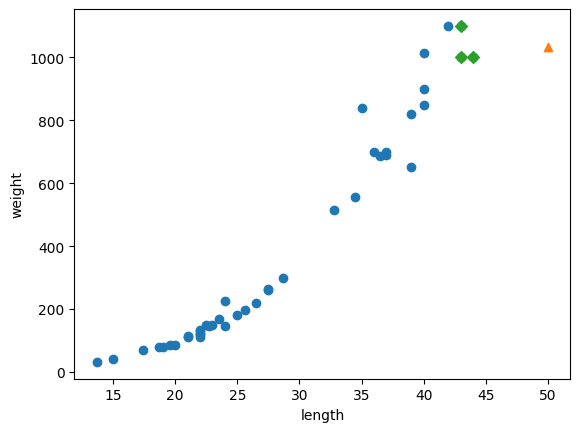

In [7]:
distance, index = knr.kneighbors([[50]]) #  type:ignore

# 참조된 3개의 이웃 출력
print(train_input[index])

# 해당 이웃을 포함하여 산점도 그리기
import matplotlib.pyplot as plt
plt.scatter(train_input, train_target)

# 해당 데이터
plt.scatter(50, 1033.33333333, marker="^")

# 해당되는 이웃
plt.scatter(train_input[index], train_target[index], marker="D")
plt.xlabel("length")
plt.ylabel("weight")
plt.show()

길이가 `50`인 데이터는 삼각형 모양의 마커로 표시되어 있고, 해당 데이터의 회귀에 사용된 데이터는 마름모 모양으로 표시되어 있다.
하지만 회귀에 사용된 데이터는 삼각형 마커의 데이터와 약 45cm가 떨어져 있으므로, 데이터는 정확하지 않다.

회귀에 사용된 샘플들의 평균을 구해보면,

In [8]:
print(np.mean(train_target[index]))

1033.3333333333333


모델이 측정한 값과 정확히 일치한다.

길이가 `500`인 농어도 산점도를 그려 확인해보면,

[[[44.]
  [43.]
  [43.]]]


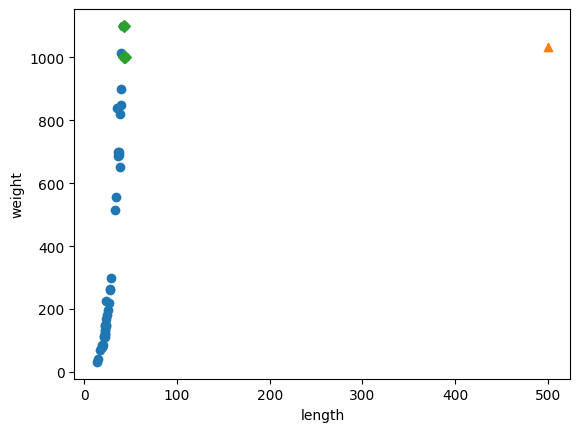

In [ ]:
distance, index = knr.kneighbors([[500]]) # type:ignore

# 참조된 3개의 이웃 출력
print(train_input[index])

# 해당 이웃을 포함하여 산점도 그리기
import matplotlib.pyplot as plt
plt.scatter(train_input, train_target)

# 해당 데이터
plt.scatter(500, 1033.33333333, marker="^")

# 해당되는 이웃
plt.scatter(train_input[index], train_target[index], marker="D")
plt.xlabel("length")
plt.ylabel("weight")
plt.show()

참조된 이웃 또한 이전과 같다.

이로써, knr 알고리즘은 모델이 학습된 범위를 넘어서면 결과를 제대로 출력하지 못한다는 것을 알아내었다.
이 문제를 해결하기 위해 현재 알고리즘보다 더 나은 알고리즘을 선택할 수 있다.

바로 **선형 회귀(linear regression)** 이다.


## 선형 회귀란?
선형 회귀는 널리 사용되는 회귀 알고리즘이다.
간단하고, 성능이 뛰어나기 때문에 초급자에게 적합한 알고리즘이다.

알고리즘의 이름에서 알 수 있듯이, 특성이 하나인 경우 특정한 직선을 학습하는 알고리즘이다.
해당 특성의 가장 보편적인 분포율 등을 계산 하여 특성을 가장 잘 나타내는 직선을 찾아 예측한다.

다음 코드의 세 그래프 중 어떤 그래프가 가장 데이터를 잘 나타내는지 확인해보자.

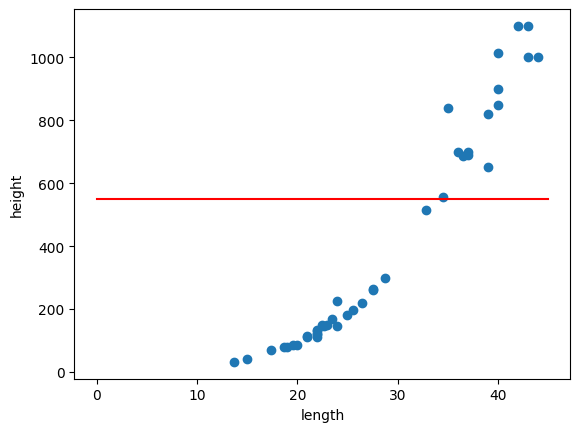

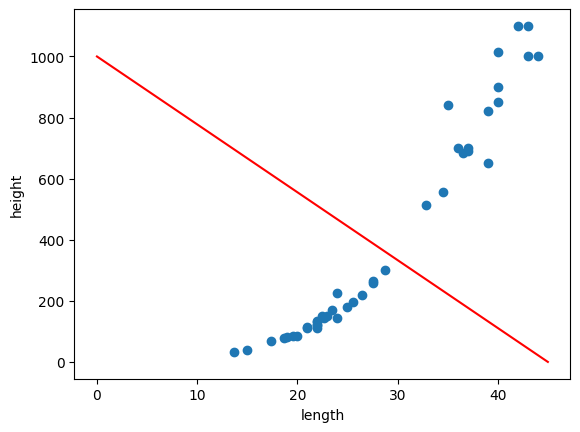

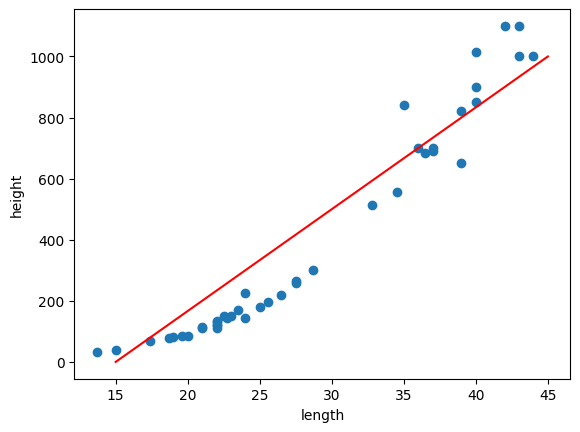

In [10]:
# 1
plt.scatter(train_input, train_target)
plt.plot([0, 45], [550, 550], 'r')
plt.xlabel("length")
plt.ylabel("height")
plt.show()

# 2
plt.scatter(train_input, train_target)
plt.plot([0, 45], [1000, 0], 'r')
plt.xlabel("length")
plt.ylabel("height")
plt.show()

# 3
plt.scatter(train_input, train_target)
plt.plot([15, 45], [0, 1000], 'r')
plt.xlabel("length")
plt.ylabel("height")
plt.show()

3개의 그래프 중 데이터를 가장 잘 표현하는 데이터는 3번 그래프로 보인다.
1번 그래프는 결과값이 항상 같게 나오고, 2번 그래프는 결과값이 완전 반대로 출력된다.
이 3번째 직선을 찾는 것이 머신러닝이다.

사이킷런은 `sklearn.linear_model` 클래스 내부에 `LinearRegressoin` 클래스로 선형 회귀가 구현되어 있다.
이 클래스의 객체를 만들어 모델을 훈련한다.

In [11]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

# 선형 회귀 모델을 훈련한다
lr.fit(train_input, train_target)

# 값을 예측한다.
lr.predict([[50]]) # type:ignore

array([1241.83860323])

모델이 훈련되었고, 예측값도 knr 때와는 다르게 다른 수치가 나왔다.
knr 알고리즘과는 달리 결과값을 정확히 예측했다.

이 알고리즘이 학습한 직선을 시각화해보자.
선형 회귀는 $y = ax + b$ 식을 사용해 직선을 하나 그린다.(일차함수)
>$b$가 $y$의 절편이고, $a$가 기울기이다. $x$의 절편은 $b$를 이항한 후 $a$로 나누어 구한다.

lr 객체의 이 기울기 값과 y 절편의 위치는 객체의 `coef_` 속성과 `intercept_` 속성에 저장된다.

In [12]:
print(lr.coef_, lr.intercept_)

[39.01714496] -709.0186449535474


결과값인 `coef_` 속성과 `intercept_` 속성을 머신러닝 알고리즘이 찾은 값이라는 의미로 **모델 파라미터**라고 부른다.
최적의 모델 파라미터를 찾는 것이 모델의 목적이므로, 이 모델은 모델 기반 학습이다.

앞에서 사용한 k- 최근접 이웃과 같은 알고리즘은 모델 파라미터가 아닌 데이터를 기반으로 계산하여 값을 정하는 알고리즘이므로
**사례 기반 학습**이다.

정해진 결과값을 시각화해보면

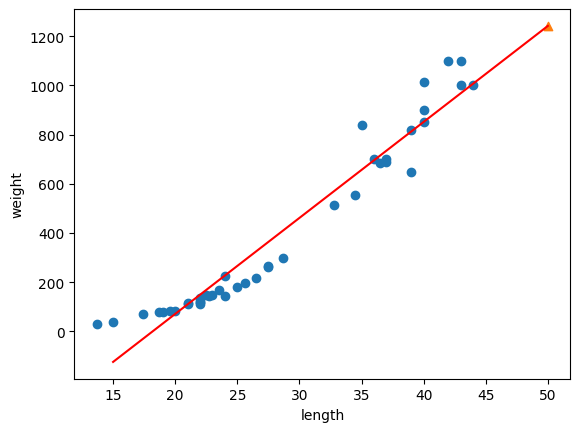

In [13]:
# 훈련 세트의 산점도를 그린다.
plt.scatter(train_input, train_target)

# 50cm 데이터
plt.scatter(50, 1241.83860323, marker="^")

# 선형 회귀가 도출한 직선
plt.plot([15, 50], [15*lr.coef_+lr.intercept_, 50*lr.coef_+lr.intercept_], "red")
plt.xlabel("length")
plt.ylabel("weight")
plt.show()

그려진 위 그래프의 직선이 이 데이터셋에서 가장 적절한 선형 그래프이다.

하지만 위의 그래프에도 문제가 있다.
그래프가 일직선이라, 전체적인 분포율을 표현하기에는 무리가 있다.
더 좋게 표현하려면, 그래프가 곡선(이차함수)를 띠고 있어야 한다.

우선, 이전 모델의 결정계수 $R^2$ 점수를 확인해보자.

In [14]:
print(lr.score(train_input, train_target))
print(lr.score(test_input, test_target))

0.9398463339976041
0.824750312331356


훈련 세트의 점수도 높지 않고, 그리고 테스트 세트의 점수는 굉장히 낮다.
위에서도 말했듯이 그래프를 2차함수로 포물선으로 그리면 문제는 해결될 것이다.

>현재 모델은 **과소적합(underfitting)** 된 상태이다.

다항 회귀를 이용해 이차함수 선형 회귀를 구현하자.

## 다항 회귀
데이터의 값들의 산점도를 확인해보면, 데이터는 일직선이기보다는 오른쪽 위로 뻗은 포물선 형태이다.
선형 회귀는 데이터에 대한 최적의 직선을 찾는다.
하지만 이번에는 최적의 곡선을 찾게 해야 한다.

다음 식을 통해 곡선 그래프 생성이 가능하다.

$
무게 = a \times 길이^2+b \times 길이+c
$

위와 같은 그래프를 그리려면, 훈련 세트인 $길이$의 제곱값이 추가되어야 한다.
>numpy는 이를 쉽게 할 수 있는 기능을 제공한다.(브로드캐스팅)

이전에 사용한 `column_stack()` 메소드를 사용해 값에 새롭게 열을 추가해 붙일 수 있다.

In [15]:
train_poly = np.column_stack((train_input ** 2, train_input))
test_poly = np.column_stack((test_input ** 2, test_input))

이전 특성인 $길이$의 $길이^2$ 값이 배열의 왼쪽 열에 추가되었다.

이제 `train_poly`를 활용해 모델을 다시 훈련해보자.
>사이킷런의 `LinearRegression` 객체 구현은 훈련 데이터에 따라 자동으로 해당 방정식에 맞는 해를 찾는다.
>일차함수의 그래프의 경우 a, b값, 이차함수의 경우 a, b, c값을 모두 구한다.
>즉, 열의 개수를 자동으로 참조하여 최적의 예측값을 도출한다.

여기서 주목할 점은, 이차함수 그래프를 찾기 위해 훈련 세트에는 제곱값을 추가했지만, 타깃값은 그대로이다.
결과는 결국 하나로 결정되기 때문이다.

In [16]:
lrp = LinearRegression()
lrp.fit(train_poly, train_target)

print(lrp.predict([[50**2, 50]])) # type:ignore

[1573.98423528]


이전에 훈련한 모델보다 너 높은 값을 예측했다.
어떤 그래프를 그렸는지도 확인해보자.

In [17]:
print(lrp.coef_, lrp.intercept_)

[  1.01433211 -21.55792498] 116.0502107827827


위의 식을 토대로 그래프를 그리면, 이차방정식의 곡선 그래프가 나온다.

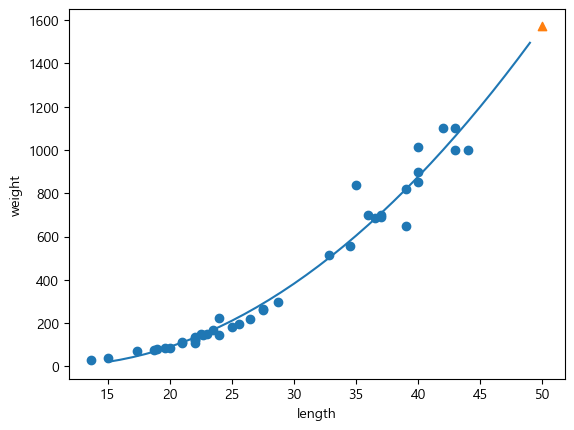

In [ ]:
# 곡선을 그리기 위에 x좌표에 해당하는 숫자 배열을 생성한다.
point = np.arange(15, 50)

# 이전 훈련 세트의 산점도 그리기
plt.scatter(train_input, train_target)

# 곡선 그래프
# 짧은 직선을 연속해서 이어서 그리면 곡선처럼 표현할 수 있다.
plt.plot(point, lrp.coef_[0]*point**2 + lrp.coef_[1]*point + lrp.intercept_)

# 해당 데이터
plt.scatter(50, 1573, marker="^")
plt.xlabel("length")
plt.ylabel("weight")
plt.show()

이전 모델보다 더 나은 그래프가 그려졌다.
훈련 세트의 분포도를 더 잘 따르고 있다.

이차방정식의 곡선형 그래프이므로 무게가 음수로 나오는 경우도 없다.
해당 모델의 결정계수 $R^2$를 확인해보면,

In [28]:
print(lrp.score(train_poly, train_target))
print(lrp.score(test_poly, test_target))

0.9706807451768623
0.9775935108325122


이전 $R^2$ 점수에 비해 현저히 높은 점수이다.
모델 개선에도 성공했다.

이로써 선형 회귀(linear regression)과 다항 회귀(polynomial regression)를 모두 알아보았다.